Saving Numeros_Favoreecidos_2019_2025_Loteria_Popular_d95e222a6d.xlsx to Numeros_Favoreecidos_2019_2025_Loteria_Popular_d95e222a6d (6).xlsx
569 sorteos cargados, del 2019-01-04 al 2025-12-02
X (variables): (500, 100)
y (objetivo): (500, 100)
Exactitud del modelo: 97.02%
Exactitud esperada solo por azar: 3.00%

Número con mayor probabilidad: 33
Probabilidad estimada: 20.05%


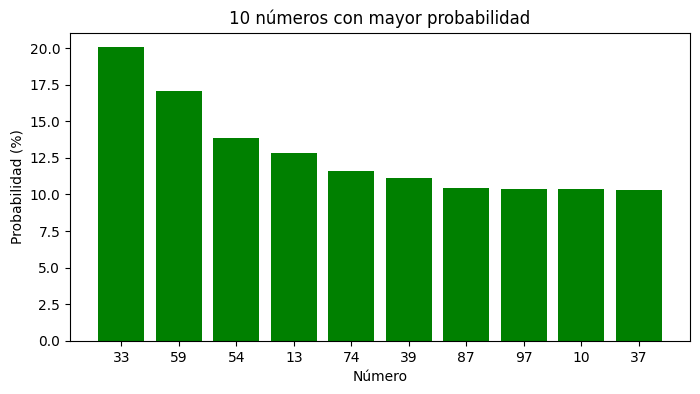

In [10]:
# Marilyn Miranda Jaen --- Grupo 4

from google.colab import files
import pandas as pd

uploaded = files.upload()
nombre_archivo = list(uploaded.keys())[0]

df = pd.read_excel(nombre_archivo, sheet_name=0)
df = df.dropna(axis=1, how="all")  # quita columnas vacías
df.columns = [str(c).strip() for c in df.columns]

col_fecha = [c for c in df.columns if "Fecha" in c][0]
df[col_fecha] = pd.to_datetime(df[col_fecha])
df = df.sort_values(col_fecha).reset_index(drop=True)

cols_numeros = [c for c in df.columns if "Número" in c and "Sorteo" not in c]

print(f"{len(df)} sorteos cargados, del {df[col_fecha].min().date()} al {df[col_fecha].max().date()}")
df.head()

# convierte a formato "tabla binaria"
rango_numeros = list(range(100))
binaria = pd.DataFrame(0, index=df.index, columns=rango_numeros)

for c in cols_numeros:
    for idx, val in df[c].items():
        if pd.notna(val):
            binaria.loc[idx, int(val)] = 1
binaria.head()

# crea las variables (features)
VENTANA = 20
N_SORTEOS = 500

muestra = binaria.tail(N_SORTEOS).reset_index(drop=True)

X = pd.DataFrame({
    f"freq_{num}": muestra[num].rolling(
        VENTANA, min_periods=1
    ).mean().shift(1).fillna(0)
    for num in rango_numeros
})

y = muestra

print("X (variables):", X.shape)
print("y (objetivo):", y.shape)

# entrena el modelo
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, shuffle=False
)

modelo = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
)

modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

# evalua el modelo
from sklearn.metrics import accuracy_score

exactitud_modelo = accuracy_score(
    y_test.values.ravel(),
    pred.ravel()
)

exactitud_azar = 3 / 100

print(f"Exactitud del modelo: {exactitud_modelo:.2%}")
print(f"Exactitud esperada solo por azar: {exactitud_azar:.2%}")

# calcula la probabilidad del proximo sorteo
ultimo = muestra.tail(VENTANA).mean()

X_proximo = pd.DataFrame([{
    f"freq_{num}": ultimo[num]
    for num in rango_numeros
}])
probabilidades = []

for estimador in modelo.estimators_:
    if 1 in estimador.classes_:
        pos = list(estimador.classes_).index(1)
        prob = estimador.predict_proba(X_proximo)[0][pos]
    else:
        prob = 0
    probabilidades.append(prob)

# guarda los resultados
resultado = pd.DataFrame({
    "numero": rango_numeros,
    "probabilidad": probabilidades
})

resultado = resultado.sort_values(
    "probabilidad",
    ascending=False
)

# muestra el numero con mayor probabilidad
numero = int(resultado.iloc[0]["numero"])
probabilidad = resultado.iloc[0]["probabilidad"]

print("\nNúmero con mayor probabilidad:", f"{numero:02d}")
print(f"Probabilidad estimada: {probabilidad:.2%}")

# obtiene los 10 mejores numeros para el grafico
top10 = resultado.head(10)

# crea el grafico
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(
    top10["numero"].astype(int).astype(str),
    top10["probabilidad"] * 100,
    color="green"
)
plt.title("10 números con mayor probabilidad")
plt.xlabel("Número")
plt.ylabel("Probabilidad (%)")
plt.show()